# Práctica 02 · Baseline vs SVM sobre un dataset real (JAC, pasajeros por aeropuerto)

**INF-8239 · Unidad 01** — aplicamos lo aprendido en el notebook guiado (baseline vs SVM) a un dataset real de la Junta de Aviación Civil (JAC) de la República Dominicana.

| Elemento | Definición |
|---|---|
| **Pregunta** | ¿Puede una SVM anticipar si un día será de *alta demanda* en un aeropuerto mejor que un baseline, y con qué costo de error? |
| **Unidad de análisis** | Un aeropuerto en un día (fila aeropuerto-día). 7 aeropuertos, 2018-01-01 a 2026-06-30 |
| **Target** | `alta_demanda` = 1 si `entrada + salida` del día supera el percentil 75 del mismo aeropuerto en el mismo año; 0 en caso contrario |
| **Variables** | Solo las conocidas *antes* del día: `aeropuerto`, `mes`, `dia_semana`, `dia` |
| **Métrica principal** | F1 macro (equilibra ambas clases; el baseline no puede engañarla con el 75 % de días normales). Secundarias: recall/precisión de la clase 1, ROC-AUC y matriz de confusión |
| **Partición** | Temporal y única: entrenamiento 2018-2024, prueba 2025-2026 (la misma para Dummy y SVM) |
| **Selección de hiperparámetros** | `GridSearchCV` con `TimeSeriesSplit` **solo sobre entrenamiento**; el test se mira una vez con el modelo elegido |

> Ejercicio académico. No sustituye un modelo operativo de planificación aeroportuaria.

In [1]:
import os, sys, json, hashlib, subprocess, warnings
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "src").exists():          # permite ejecutar desde notebooks/ o desde la raíz
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

from src.inf8239_u01.data import URL_JAC, clean_jac, ensure_dataset, load_raw
from src.inf8239_u01.evaluate import compare_models, evaluate
from src.inf8239_u01.features import (EXCLUDED_COLUMNS, FEATURES, FEATURES_CAT, FEATURES_NUM,
                                      LEAKAGE_COLUMNS, TARGET, add_calendar_features,
                                      build_target, temporal_split)
from src.inf8239_u01.models import build_dummy, build_search, build_svm_jac

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
print("Raíz del proyecto:", ROOT)

Raíz del proyecto: /home/claude/INF8239_U01


## 1. Descarga y procedencia

`ensure_dataset` descarga el CSV desde la JAC **solo si** `data/raw/dataset.csv` no existe. Fuente, fecha de acceso, hash y licencia (**ODbL v1.0**, con atribución a la JAC) están en `docs/PROCEDENCIA_LICENCIA.md`.

In [2]:
path = ensure_dataset(URL_JAC)
print("Fuente :", URL_JAC)
print("Archivo:", path, "|", path.stat().st_size, "bytes")
print("SHA-256:", hashlib.sha256(path.read_bytes()).hexdigest())

Fuente : https://jac.gob.do/wp-content/uploads/2026/07/Movimiento-de-Entrada-y-Salida-de-Pasajeros-por-Aeropuertos-Junta-de-Aviacion-Civil-JAC-2018-2026.csv
Archivo: data/raw/dataset.csv | 814383 bytes
SHA-256: a5ecfb704a24bf9362c70d065701ccbc27d4e75bc9b27a3e1cdd07e213b0e712


## 2. Auditoría del archivo crudo

Revisamos forma, tipos, extremos, valores especiales y duplicados **antes** de transformar nada.

In [3]:
raw = load_raw(path)
print(raw.shape)
print(raw.dtypes)
display(raw.head())
display(raw.tail())
assert not raw.empty

guiones = {c: int((raw[c].astype(str).str.strip() == "-").sum()) for c in ("entrada", "salida")}
print("Valores '-' (sin operaciones):", guiones)
print("Duplicados exactos:", raw.duplicated().sum())
print("Nombres de aeropuerto en el CSV:", raw["aeropuerto_original"].nunique())

audit = pd.DataFrame({
    "tipo": raw.dtypes.astype(str),
    "ausentes": raw.isna().sum(),
    "porcentaje_ausente": (raw.isna().mean() * 100).round(2),
    "unicos": raw.nunique(dropna=False),
}).sort_values("porcentaje_ausente", ascending=False)
display(audit)

(19971, 6)
aeropuerto_original      str
entrada                  str
salida                   str
dia                    int64
mes_nombre               str
anio                   int64
dtype: object


,aeropuerto_original,entrada,salida,dia,mes_nombre,anio
0,Del Cibao,2136,1956,1,Enero,2018
1,Del Cibao,2017,2562,2,Enero,2018
2,Del Cibao,2490,2485,3,Enero,2018
3,Del Cibao,1649,1385,4,Enero,2018
4,Del Cibao,821,1324,5,Enero,2018


,aeropuerto_original,entrada,salida,dia,mes_nombre,anio
19966,Santo Domingo - Las Américas,8341,7551,26,Junio,2026
19967,Santo Domingo - Las Américas,8859,8662,27,Junio,2026
19968,Santo Domingo - Las Américas,9141,8988,28,Junio,2026
19969,Santo Domingo - Las Américas,8826,7996,29,Junio,2026
19970,Santo Domingo - Las Américas,9301,9279,30,Junio,2026


Valores '-' (sin operaciones): {'entrada': 736, 'salida': 586}
Duplicados exactos: 0
Nombres de aeropuerto en el CSV: 11


,tipo,ausentes,porcentaje_ausente,unicos
aeropuerto_original,str,0,0.0,11
entrada,str,0,0.0,7643
salida,str,0,0.0,7657
dia,int64,0,0.0,31
mes_nombre,str,0,0.0,12
anio,int64,0,0.0,9


**Hallazgos de la auditoría**

- `Entrada` y `Salida` llegan como **texto** porque traen el guion `" -   "` (736 y 586 veces). El mínimo numérico del archivo es 1 y nunca aparece un 0 explícito, así que el guion se interpreta como **cero operaciones**.
- Hay **11 nombres** de aeropuerto pero solo **7 aeropuertos**: los nombres de 2018 cambian desde 2019 (`Del Cibao` → `Santiago`, `La Isabela` → `Santo Domingo - El Higüero`, etc.) y no se solapan en años. Se armonizan.
- No hay valores ausentes (`NaN`) ni duplicados exactos.

## 3. Limpieza mínima y justificada

La limpieza **no elimina filas**: convierte tipos, armoniza nombres y construye la fecha.

(19971, 8) | 2018-01-01 -> 2026-06-30
Aeropuertos armonizados: 7
Duplicados aeropuerto-fecha: 0
Días con total = 0 (se conservan, son días de baja demanda): 146


aeropuerto,La Romana,Puerto Plata,Punta Cana,Samaná - El Catey,Santiago,Santo Domingo - El Higüero,Santo Domingo - Las Américas
anio,,,,,,,
2018,324,365,365,232,365,365,365
2019,345,365,365,230,365,365,365
2020,247,268,320,111,338,360,366
2021,360,365,365,139,365,365,365
2022,318,354,365,219,365,365,365
2023,361,355,365,274,365,365,365
2024,338,366,366,260,366,366,366
2025,353,365,365,213,365,365,365
2026,178,181,181,153,181,181,181


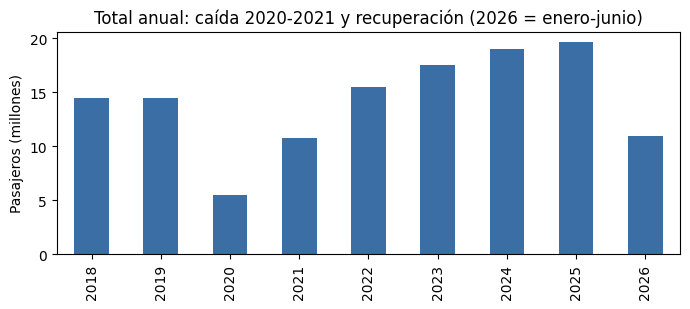

In [4]:
df = clean_jac(raw)
print(df.shape, "|", df["fecha"].min().date(), "->", df["fecha"].max().date())
print("Aeropuertos armonizados:", df["aeropuerto"].nunique())
print("Duplicados aeropuerto-fecha:", df.duplicated(["aeropuerto", "fecha"]).sum())
print("Días con total = 0 (se conservan, son días de baja demanda):", int((df["total"] == 0).sum()))

display(pd.crosstab(df["anio"], df["aeropuerto"]))

anual = df.groupby("anio")["total"].sum() / 1e6
fig, ax = plt.subplots(figsize=(7, 3.2))
anual.plot.bar(ax=ax, color="#3b6ea5")
ax.set_ylabel("Pasajeros (millones)"); ax.set_xlabel("")
ax.set_title("Total anual: caída 2020-2021 y recuperación (2026 = enero-junio)")
plt.tight_layout(); plt.show()

## 4. Target y unidad de análisis

- **Unidad de análisis:** un aeropuerto en un día.
- **Target `alta_demanda`:** 1 si `total = entrada + salida` supera el **percentil 75 del mismo aeropuerto en el mismo año**.

¿Por qué por aeropuerto **y año**? Con un umbral global, el aeropuerto decidiría todo (Punta Cana siempre alto). Con un umbral fijo calculado en 2018-2024, el crecimiento del tráfico haría que en 2025-2026 el ~44 % de los días fueran «altos»: el test sería una tarea distinta al entrenamiento. Con el umbral por aeropuerto-año, «alta» significa *alta respecto a su propio año* y el balance se mantiene en ~25 %.

**Limitación honesta:** el umbral de un año usa la distribución de ese año, que en producción no se conocería de antemano. Aquí es una *definición de la etiqueta* (no entra en las variables), pero conviene tenerlo presente al interpretar el resultado.

In [5]:
df = build_target(add_calendar_features(df))
y_all = df[TARGET]
assert TARGET in df.columns and y_all.notna().all() and y_all.nunique() >= 2

print(y_all.value_counts(dropna=False).rename("filas").to_frame().assign(proporcion=lambda t: (t["filas"] / t["filas"].sum()).round(3)))
por_anio = df.groupby("anio")[TARGET].mean().round(3)
display(por_anio.to_frame("proporcion_alta_demanda").T)

ejemplo = df[(df["aeropuerto"] == "Punta Cana") & (df["anio"] == 2025)].iloc[[0, 1, 2]]
display(ejemplo[["fecha", "aeropuerto", "total", "umbral_p75", TARGET]])

              filas  proporcion
alta_demanda                   
0             14992       0.751
1              4979       0.249


anio,2018,2019,2020,2021,2022,2023,2024,2025,2026
proporcion_alta_demanda,0.249,0.25,0.251,0.249,0.25,0.249,0.25,0.248,0.248


,fecha,aeropuerto,total,umbral_p75,alta_demanda
16346,2025-01-01,Punta Cana,31239,33474.0,0
16353,2025-01-02,Punta Cana,36354,33474.0,1
16360,2025-01-03,Punta Cana,34825,33474.0,1


## 5. Identificadores y fugas

| Columna | Decisión | Justificación |
|---|---|---|
| `entrada`, `salida`, `total` | **Fuera de X (fuga)** | Son el resultado del día; `total` genera el target. Con ellas el problema sería trivial y no serviría para anticipar |
| `umbral_p75` | Fuera de X | Derivada directa del target |
| `fecha` | Fuera de X | Solo ordena y parte en el tiempo; como número extrapola mal |
| `anio` | Fuera de X | El target ya es relativo al año; 2025-2026 son años no vistos en entrenamiento |
| `aeropuerto` | **Variable** | Categoría de 7 valores conocida de antemano; no identifica filas |
| `mes`, `dia_semana`, `dia` | **Variables** | Calendario: se conocen antes del día a predecir |

El dataset **no trae ningún identificador de fila** (ID de vuelo, pasajero o registro).

In [6]:
assert set(FEATURES).isdisjoint(EXCLUDED_COLUMNS)
assert set(FEATURES).isdisjoint(LEAKAGE_COLUMNS)
assert TARGET not in FEATURES

roles = pd.DataFrame({
    "columna": df.columns,
    "rol": ["variable" if c in FEATURES else ("target" if c == TARGET else "excluida") for c in df.columns],
})
display(roles.set_index("columna").T)
print("Categóricas:", FEATURES_CAT, "| Numéricas:", FEATURES_NUM)

columna,fecha,aeropuerto,entrada,salida,total,dia,mes,anio,dia_semana,umbral_p75,alta_demanda
rol,excluida,variable,excluida,excluida,excluida,variable,variable,excluida,variable,excluida,target


Categóricas: ['aeropuerto', 'mes', 'dia_semana'] | Numéricas: ['dia']


## 6. Partición temporal única

Se hace **una sola vez**. El baseline y la SVM usan exactamente las mismas filas de entrenamiento y de prueba.

In [7]:
X_train, X_test, y_train, y_test = temporal_split(df)
ordenado = df.sort_values(["fecha", "aeropuerto"]).reset_index(drop=True)
f_train = ordenado.loc[X_train.index, "fecha"]; f_test = ordenado.loc[X_test.index, "fecha"]

print("train:", X_train.shape, f_train.min().date(), "->", f_train.max().date(), "| positivos:", round(y_train.mean(), 3))
print("test :", X_test.shape,  f_test.min().date(),  "->", f_test.max().date(),  "| positivos:", round(y_test.mean(), 3))
assert f_train.max() < f_test.min()                 # sin solape temporal
assert set(X_train.index).isdisjoint(X_test.index)  # sin filas compartidas
assert list(X_train.columns) == FEATURES

train: (16344, 4) 2018-01-01 -> 2024-12-31 | positivos: 0.25
test : (3627, 4) 2025-01-01 -> 2026-06-30 | positivos: 0.248


## 7. Pipelines: el preprocesamiento vive dentro

Imputación, escalado y one-hot se **ajustan solo con el entrenamiento** de cada partición (y de cada fold en la validación cruzada), porque forman parte del `Pipeline`. Ninguna transformación se aplica a los datos antes de dividirlos.

In [8]:
dummy, svm = build_dummy(), build_svm_jac(C=1, gamma="scale")
for nombre, pipe in {"dummy": dummy, "svm": svm}.items():
    assert isinstance(pipe.named_steps["prep"], ColumnTransformer)
    print(nombre, "->", list(pipe.named_steps))
svm

dummy -> ['prep', 'model']
svm -> ['prep', 'model']


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains s

## 8. Baseline vs SVM (misma partición)

In [9]:
comparacion = compare_models({"dummy": dummy, "svm_base": svm}, X_train, y_train, X_test, y_test)
display(comparacion.round(4))

svm_base = build_svm_jac(C=1, gamma="scale").fit(X_train, y_train)
print(classification_report(y_test, svm_base.predict(X_test), digits=4))

,f1_macro,f1_alta,precision_alta,recall_alta,accuracy,roc_auc,tn,fp,fn,tp
dummy,0.4294,0.0000,0.0000,0.0000,0.7524,NaN,2729.0,0.0,898.0,0.0
svm_base,0.7615,0.6256,0.7372,0.5434,0.8390,0.8655,2555.0,174.0,410.0,488.0


              precision    recall  f1-score   support

           0     0.8617    0.9362    0.8974      2729
           1     0.7372    0.5434    0.6256       898

    accuracy                         0.8390      3627
   macro avg     0.7994    0.7398    0.7615      3627
weighted avg     0.8309    0.8390    0.8301      3627



**Lectura.**

- **Baseline (`most_frequent`)** predice siempre «día normal»: acierta el 75.2 % de los días (exactitud alta y engañosa) pero **no detecta ni un solo día de alta demanda** (recall 0, F1 de la clase 1 = 0). Su F1 macro es 0.429.
- **SVM base (C=1, gamma=scale):** F1 macro **0.762** y ROC-AUC 0.866. La mejora de +0.33 en F1 macro es real y no viene del desbalance.
- El costo: detecta poco más de la mitad de los días de alta demanda (recall 0.543) con precisión 0.737.

## 9. GridSearchCV (solo con entrenamiento)

9 combinaciones (`C` ∈ {0.1, 1, 10} × `gamma` ∈ {scale, 0.01, 0.1}) × 4 folds temporales = 36 ajustes, con `scoring="f1_macro"`. `TimeSeriesSplit` respeta el orden: cada fold entrena con el pasado y valida con el futuro inmediato (una CV aleatoria mezclaría días vecinos y daría un resultado optimista).

In [10]:
search = build_search(n_splits=4)
search.fit(X_train, y_train)
print("Mejores hiperparámetros:", search.best_params_)
print("F1 macro CV:", round(search.best_score_, 4))

cols = ["param_model__C", "param_model__gamma", "mean_test_score", "std_test_score",
        "mean_train_score", "rank_test_score"]
cv_results = (pd.DataFrame(search.cv_results_)[cols]
              .sort_values("rank_test_score").reset_index(drop=True)
              .rename(columns={"param_model__C": "C", "param_model__gamma": "gamma",
                               "mean_test_score": "F1_macro_CV", "std_test_score": "desv_CV",
                               "mean_train_score": "F1_macro_train", "rank_test_score": "rank"}))
display(cv_results.round(4))

Mejores hiperparámetros: {'model__C': 10, 'model__gamma': 0.1}
F1 macro CV: 0.6968


,C,gamma,F1_macro_CV,desv_CV,F1_macro_train,rank
0,10.0,0.1,0.6968,0.0584,0.7771,1
1,10.0,scale,0.6951,0.0554,0.8070,2
2,1.0,scale,0.6944,0.0615,0.7683,3
3,1.0,0.1,0.6262,0.0636,0.6795,4
4,0.1,scale,0.4728,0.0584,0.4861,5
5,10.0,0.01,0.4389,0.0124,0.4586,6
6,0.1,0.1,0.4300,0.0060,0.4266,7
7,0.1,0.01,0.4300,0.0060,0.4266,7
8,1.0,0.01,0.4300,0.0060,0.4266,7


**Lectura de la tabla**

- **Empate práctico en la cima:** (C=10, γ=0.1) = 0.6968, (C=10, γ=scale) = 0.6951 y (C=1, γ=scale) = 0.6944. Las diferencias (~0.002) son mucho menores que la desviación entre folds (~0.055-0.06): son **estadísticamente indistinguibles**.
- **Subajuste:** con `C=0.1` o `γ=0.01` el F1 macro cae a ~0.43-0.47, el mismo nivel que el baseline (0.43): el modelo casi no separa las clases.
- **El óptimo está en el borde del grid** (C=10 y γ=0.1 son los valores máximos probados). Un siguiente paso razonable es ampliar la búsqueda hacia valores mayores.
- **Brecha train-CV pequeña** (0.777 vs 0.697 en el mejor): no hay sobreajuste fuerte.

,f1_macro,f1_alta,precision_alta,recall_alta,accuracy,roc_auc,tn,fp,fn,tp
dummy,0.4294,0.0000,0.0000,0.0000,0.7524,NaN,2729.0,0.0,898.0,0.0
svm_base,0.7615,0.6256,0.7372,0.5434,0.8390,0.8655,2555.0,174.0,410.0,488.0
svm_grid,0.7595,0.6249,0.7139,0.5557,0.8348,0.8613,2529.0,200.0,399.0,499.0


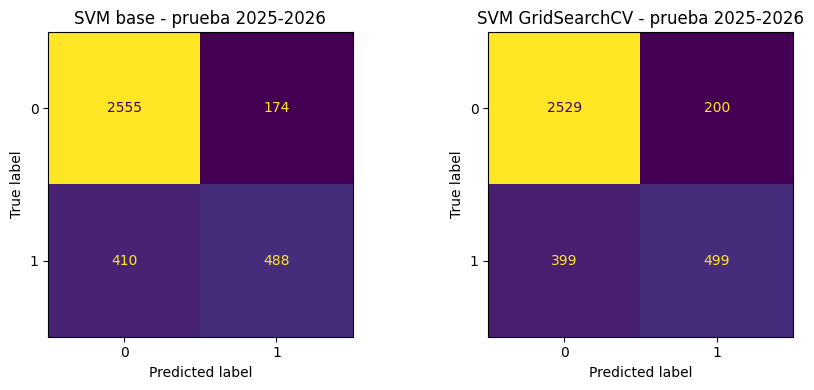

In [11]:
mejor = search.best_estimator_
comparacion.loc["svm_grid"] = pd.Series(evaluate(mejor, X_test, y_test))
display(comparacion.round(4))

fig, ejes = plt.subplots(1, 2, figsize=(9, 4))
for eje, (titulo, modelo) in zip(ejes, [("SVM base", svm_base), ("SVM GridSearchCV", mejor)]):
    ConfusionMatrixDisplay.from_predictions(y_test, modelo.predict(X_test), ax=eje, colorbar=False)
    eje.set_title(f"{titulo} - prueba 2025-2026")
plt.tight_layout(); plt.show()

## 10. Interpretación de la matriz de confusión y costo de los errores

Clase positiva = 1 (**alta demanda**). Matriz de la SVM elegida por CV (3 627 días de prueba):

| | Pred. normal (0) | Pred. alta (1) |
|---|---|---|
| **Real normal (0)** | 2 529 (TN) | **200 (FP)** |
| **Real alta (1)** | **399 (FN)** | 499 (TP) |

- **Falso positivo (200):** se anticipa un día de alta demanda que no lo fue → se sobredimensiona personal o capacidad (costo de recursos ociosos).
- **Falso negativo (399):** un día de alta demanda no se anticipa → filas, congestión y servicio insuficiente. **Es el error más costoso** para la planificación, y hay el doble que de falsos positivos: el modelo es conservador (recall 0.556).
- La SVM detecta unos 56 de cada 100 días de alta demanda; de cada 100 alertas, 71 son correctas.
- **No se ajusta el umbral mirando esta matriz.** Si el costo del FN fuera mucho mayor, se podría mover el umbral de `decision_function` o usar `class_weight`, decidiéndolo con validación cruzada dentro del entrenamiento, no con el test.

**Sobre elegir hiperparámetros:** el modelo del grid (F1 macro 0.7595) no supera al SVM base (0.7615) en test. Esa diferencia de 0.002 es ruido; no se vuelve a buscar hiperparámetros mirando la prueba. La decisión se apoya en la CV, donde los tres mejores están empatados.

In [12]:
# Consistencia con la corrida de pract02.py (mismas semillas y partición)
ref = json.loads(Path("reports/metrics.json").read_text(encoding="utf-8"))
for nombre in ("dummy", "svm_base", "svm_grid"):
    for metrica in ("f1_macro", "recall_alta", "accuracy"):
        assert abs(comparacion.loc[nombre, metrica] - ref["metricas_test"][nombre][metrica]) < 1e-3, (nombre, metrica)
assert abs(search.best_score_ - ref["cv_f1_macro"]) < 1e-3
print("El notebook reproduce las métricas guardadas en reports/metrics.json")

El notebook reproduce las métricas guardadas en reports/metrics.json


## 11. Pruebas aprobadas y commits

La suite de `pytest` cubre descarga, limpieza, target, fugas, partición temporal, pipeline, comparación con la misma partición y CV temporal.

In [13]:
res = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "--tb=short", "-rf",
                      "-p", "no:cacheprovider"], capture_output=True, text=True, cwd=ROOT)
lineas = res.stdout.strip().splitlines()
print(lineas[-1])
if res.returncode != 0:  # mostrar solo lo esencial: qué prueba falló y por qué
    print("\n".join([l for l in lineas if l.startswith(("FAILED", "ERROR", "E  "))][:30]))
    print("stderr:", res.stderr[-500:])
assert res.returncode == 0, "Fallaron pruebas; ejecuta en la terminal: python -m pytest -x -q --tb=short"

try:
    log = subprocess.run(["git", "log", "--oneline"], capture_output=True, text=True, cwd=ROOT, check=True).stdout
    print("\nCommits hasta esta celda:\n" + log)
    n_commits = len(log.strip().splitlines())
except Exception as e:
    log, n_commits = "", None
    print("git no disponible:", e)

25 passed in 2.33s

Commits hasta esta celda:
c8b8b0d docs: registrar licencia ODbL v1.0 del dataset y su aviso de atribución
3e25421 docs: README con instalación, descarga, target, métrica, ejecución y pruebas
e54a065 docs: notebook completo y ejecutado de la práctica 02
4c9e217 docs: ficha de procedencia/licencia y diccionario de datos
c6fca06 feat: pract02.py de extremo a extremo con evidencias en reports/
7bc6d41 test(models): 8 pruebas de pipeline, misma partición, FP/FN y CV temporal
6ca7b5d feat(models): pipelines Dummy y SVM con preprocesamiento interno y evaluación común
f441bf8 test(target): 6 pruebas de umbral, fugas y partición temporal sin solape
b99c3f4 feat(target): variables de calendario, target alta_demanda y split temporal
94ad42a test(data): 9 pruebas de descarga, limpieza y armonización de aeropuertos
821169e feat(data): descarga, lectura y limpieza del dataset JAC
11e8e0d chore: estructura del proyecto, requirements, pytest.ini y .gitignore



## 12. Checklist de calidad

In [14]:
import re
n_pruebas = int(re.search(r"(\d+) passed", res.stdout).group(1))
checks = {
    "Target y unidad de análisis definidos": TARGET == "alta_demanda" and df.duplicated(["aeropuerto", "fecha"]).sum() == 0,
    "Identificadores y fugas justificados (X sin entrada/salida/total/fecha/anio)": set(FEATURES).isdisjoint(EXCLUDED_COLUMNS),
    "Preprocesamiento dentro de Pipeline": all(isinstance(p.named_steps["prep"], ColumnTransformer) for p in (dummy, svm, mejor)),
    "Dummy y SVM usan la misma partición": list(comparacion.index[:2]) == ["dummy", "svm_base"] and int(comparacion.loc["dummy", ["tn", "fp", "fn", "tp"]].sum()) == len(y_test) == int(comparacion.loc["svm_base", ["tn", "fp", "fn", "tp"]].sum()),
    f"Al menos tres pruebas ({n_pruebas} aprobadas)": n_pruebas >= 3,
    f"Commits significativos ({n_commits})": n_commits is None or n_commits >= 5,
}
display(pd.Series(checks, name="cumple").to_frame())
assert all(checks.values())

,cumple
Target y unidad de análisis definidos,True
Identificadores y fugas justificados (X sin entrada/salida/total/fecha/anio),True
Preprocesamiento dentro de Pipeline,True
Dummy y SVM usan la misma partición,True
Al menos tres pruebas (25 aprobadas),True
Commits significativos (12),True


## 13. Conclusiones

**Respuesta a la pregunta.** Sí: una SVM anticipa los días de alta demanda claramente mejor que el baseline (F1 macro 0.76 frente a 0.43; ROC-AUC 0.86), usando solo variables de calendario y el aeropuerto. Pero el costo de error no es despreciable: detecta ~55 % de los días altos y comete 399 falsos negativos en 3 627 días de prueba, que son el error más caro.

**Lo que aprendimos con datos reales**

- El baseline puede parecer bueno (75 % de exactitud) y no servir para nada; el F1 macro y el recall de la clase 1 lo exponen.
- Con datos en el tiempo, el **split temporal** y el umbral por aeropuerto-año importan más que el modelo: un umbral fijo habría dejado el test con 44 % de positivos.
- La búsqueda de hiperparámetros dio un empate práctico entre tres configuraciones; el modelo del grid no mejora al base en el test, y eso es un resultado aceptable, no un fallo.
- Representar `mes` y `dia_semana` como categorías (one-hot) rinde mucho más que tratarlos como números.

**Limitaciones**

- Solo hay 4 variables de calendario: no incluyen feriados, clima ni el calendario de vuelos/temporadas, que probablemente explican buena parte de la demanda.
- El umbral por aeropuerto-año usa la distribución de ese año (definición de etiqueta, no variable), que no se conocería con antelación en producción.
- El óptimo del grid está en el borde: no se exploró `C > 10` ni `gamma > 0.1`.
- El CV F1 macro (0.70) es más bajo que el del test (0.76): los primeros folds entrenan con pocos datos y cubren 2020-2021 (pandemia). Es una hipótesis razonable, no una medición.
- Si se publica el dataset limpio, hay que ofrecerlo bajo la misma ODbL y con atribución a la JAC (ver `docs/PROCEDENCIA_LICENCIA.md`).

**Siguientes pasos:** añadir feriados y temporadas, ampliar el grid, probar `class_weight` o mover el umbral con validación temporal, y comparar con un modelo de árboles.